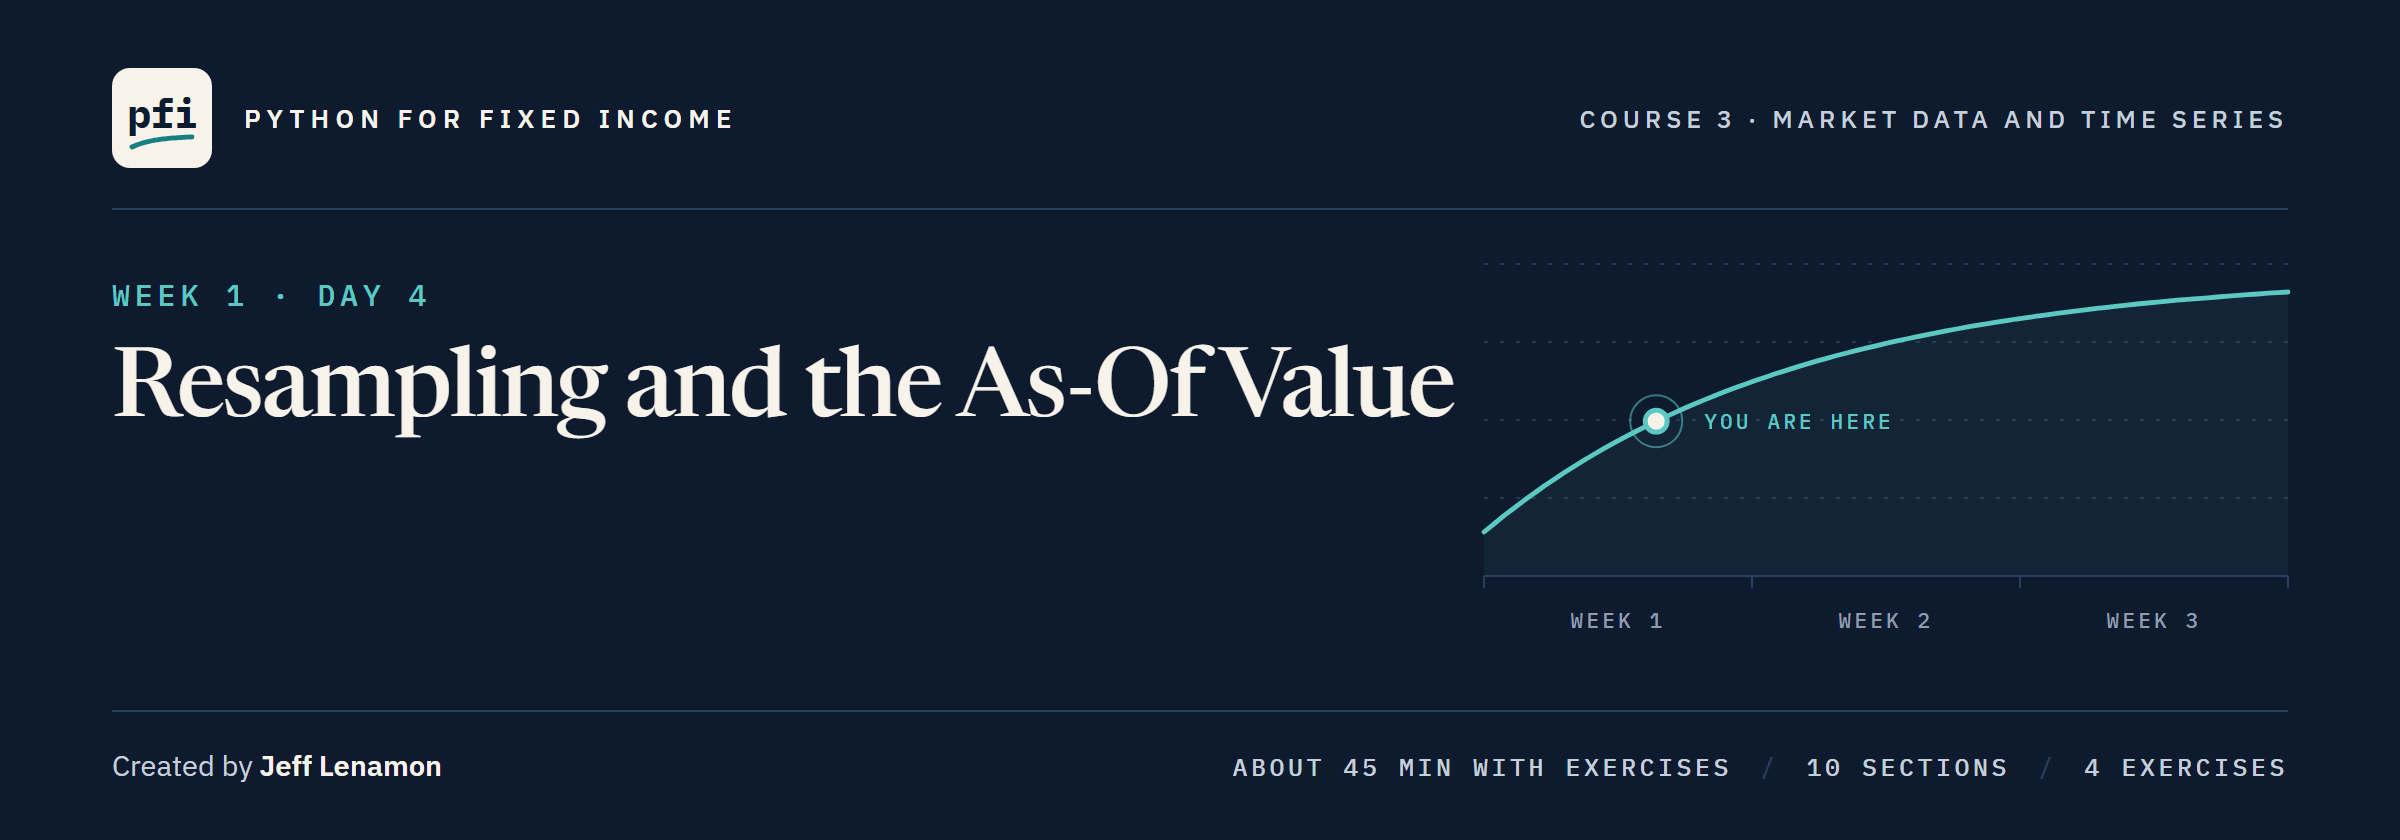

# Resampling and the As-Of Value

Week 1, Day 4. One number for a week or a month: which observation stands for it, the date it really comes from, a week with no Friday, what a calendar grid does to a holiday, and the value as of any date, tied to Excel.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week1/day4/04_resampling_and_the_as_of_value.ipynb)

### The Desk Lead's Note

> The monthly pack shows one 10-year yield per month, and the weekly sheet one per week. Tell me which observation stands for each, and write beside it the date it really comes from. No label on a day the market never had. Show me a week with no Friday. Some reports run on a holiday or a Saturday, so give me the value as of any date, and the date it came from. Then the 2026 month-end 10-year and 2s10s, tied to Excel. Two tested functions in the module, and keep any half-finished idea out of the commit.

No key is needed today: every number comes from the Treasury file.

**A month's number is its last observation, and its label is the date of that observation.**

### Today's Work Folder

Q. Where does today's work happen?

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py, its tests,
# and their Git history as notebook 03 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(4)

Work folder pfi_course3_04_k4w7q2xr: 4 data files, Course 2's bondmath.py, marketdata.py as notebook 03 left it, 3 commits


`start_day(4)` copied in the data files and notebook 03's module.

### The Tests Pass Before We Start

In [2]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.............                                                            [100%]
13 passed in 0.50s



### Imports and the Treasury File

In [3]:
import importlib

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import marketdata as md

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])

In [4]:
# the Treasury file as in notebook 03; ten is its 10 Yr column, in percent
treasury = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                       float_precision='round_trip')
ten = treasury['10 Yr']
print(len(ten), 'rows, from', ten.index[0].date(), 'to', ten.index[-1].date())

2940 rows, from 2015-01-02 to 2026-10-02


## Your Route Through Day 4

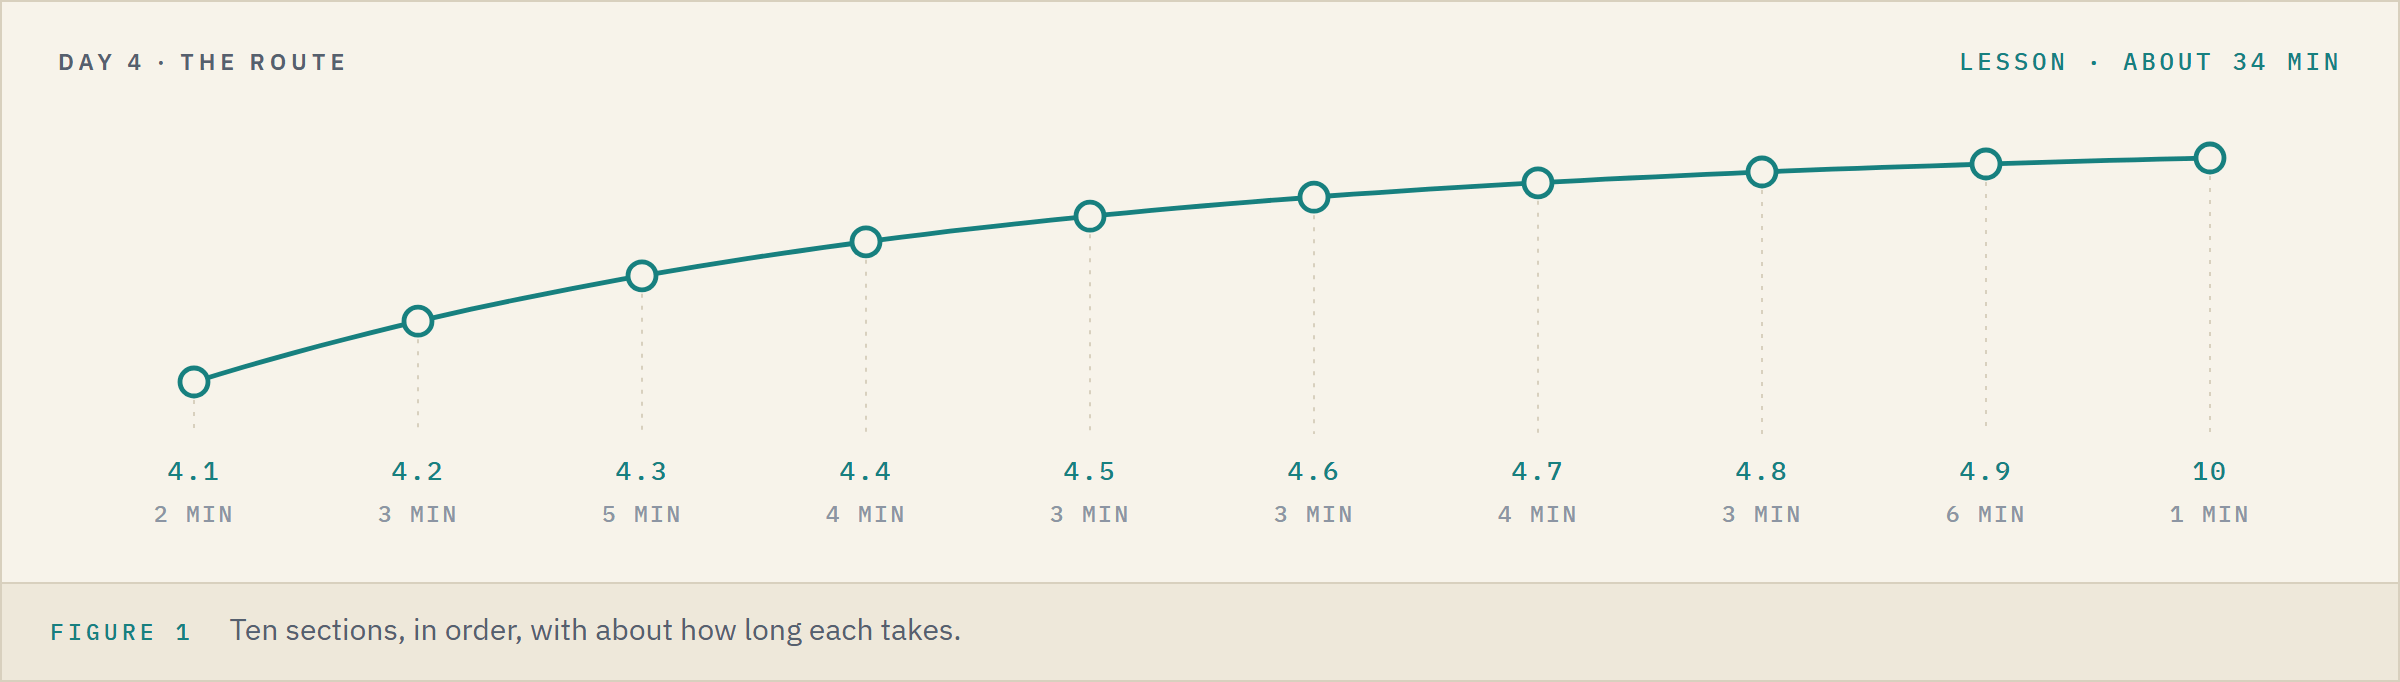

<table align="left">
<tr><th align="left"></th><th align="left">Section</th><th align="left">About</th></tr>
<tr><td align="left">4.1</td><td align="left">Which Observation Stands for a Month</td><td align="left">2 min</td></tr>
<tr><td align="left">4.2</td><td align="left">The Label <code>resample</code> Prints</td><td align="left">3 min</td></tr>
<tr><td align="left">4.3</td><td align="left"><code>last_per_period</code>: Each Month With Its Own Date</td><td align="left">5 min</td></tr>
<tr><td align="left">4.4</td><td align="left">The Week of Good Friday 2025</td><td align="left">4 min</td></tr>
<tr><td align="left">4.5</td><td align="left"><code>asfreq</code>: a Grid of Dates</td><td align="left">3 min</td></tr>
<tr><td align="left">4.6</td><td align="left">The As-Of Value: <code>value_as_of</code></td><td align="left">3 min</td></tr>
<tr><td align="left">4.7</td><td align="left">Before the First Row, and a Column With Gaps</td><td align="left">4 min</td></tr>
<tr><td align="left">4.8</td><td align="left">Month-End Levels for 2026</td><td align="left">3 min</td></tr>
<tr><td align="left">4.9</td><td align="left">Park an Experiment: <code>git stash</code></td><td align="left">6 min</td></tr>
<tr><td align="left">10</td><td align="left">Bring It Home</td><td align="left">1 min</td></tr>
</table>
<br clear="left">

**Time.** About 34 minutes for the lesson, then about 12 for the four exercises.

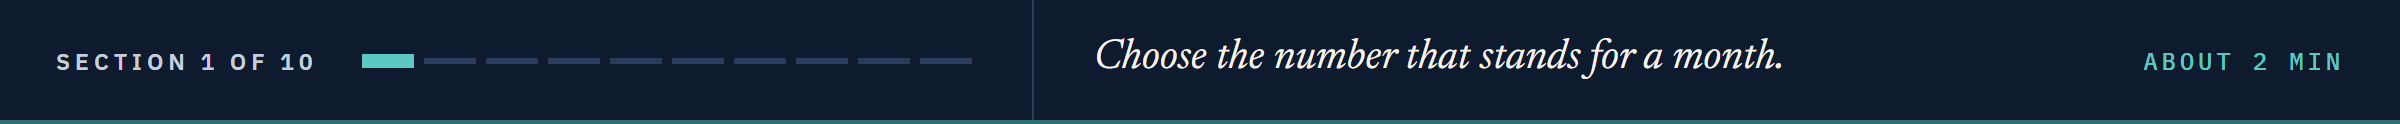

## 4.1 Which Observation Stands for a Month

Notebook 03 settled which days the market had.
Now one number has to stand for a whole month.

### September, Four Ways

In [5]:
# September 2026's rows, and four candidates for its one number
september = ten.loc['2026-09']
print(len(september), 'rows | first', september.iloc[0], '| last', september.iloc[-1],
      '| mean', round(september.mean(), 3), '| high', september.max())

21 rows | first 4.79 | last 5.29 | mean 4.989 | high 5.29


**Excel side by side.** The Treasury file opened in Excel: dates in A2:A2941, the 2 Yr in column I, the 5 Yr in K, the 10 Yr in M.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">The first row on or after 1 September</td><td align="left"><code>september.iloc[0]</code></td><td align="left"><code>=XLOOKUP(DATE(2026,9,1),$A$2:$A$2941,M2:M2941,,1)</code></td><td align="left">4.79</td></tr>
<tr><td align="left">The mean</td><td align="left"><code>september.mean()</code></td><td align="left"><code>=AVERAGEIFS(M2:M2941,$A$2:$A$2941,"&gt;="&amp;DATE(2026,9,1),$A$2:$A$2941,"&lt;="&amp;DATE(2026,9,30))</code></td><td align="left">4.989</td></tr>
<tr><td align="left">The high</td><td align="left"><code>september.max()</code></td><td align="left"><code>=MAXIFS(M2:M2941,$A$2:$A$2941,"&gt;="&amp;DATE(2026,9,1),$A$2:$A$2941,"&lt;="&amp;DATE(2026,9,30))</code></td><td align="left">5.29</td></tr>
</table>
<br clear="left">

`XLOOKUP`'s last argument, 1, is its match mode: the date itself or the next one after it.
`AVERAGEIFS` and `MAXIFS` average, or take the largest of, the rows that meet every condition.

### Draw September

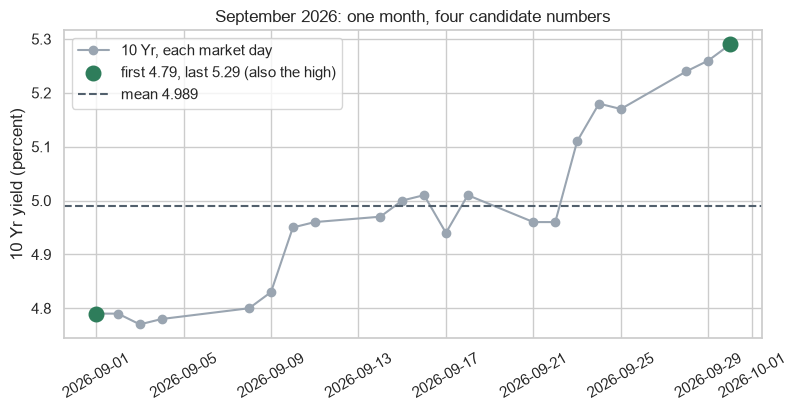

In [6]:
# the 21 rows, the first and last marked, the mean dashed
ends = september.iloc[[0, -1]]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(september.index, september, marker='o', color='#9AA5B1', label='10 Yr, each market day')
ax.scatter(ends.index, ends, s=110, color='#2E7D5B', zorder=3,
           label='first 4.79, last 5.29 (also the high)')
ax.axhline(september.mean(), color='#52606D', linestyle='--', label='mean 4.989')
ax.set_title('September 2026: one month, four candidate numbers')
ax.set_ylabel('10 Yr yield (percent)')
ax.tick_params(axis='x', rotation=30)
ax.legend()
plt.show()

The mean sits on no day at all, and the first row is the month's open.
The course takes the last observation: by calendar month, `'ME'`, and by week ending Friday, `'W-FRI'`.

**A month's number is its close: 5.29 on 2026-09-30, not the 4.989 mean or the 4.79 open.**

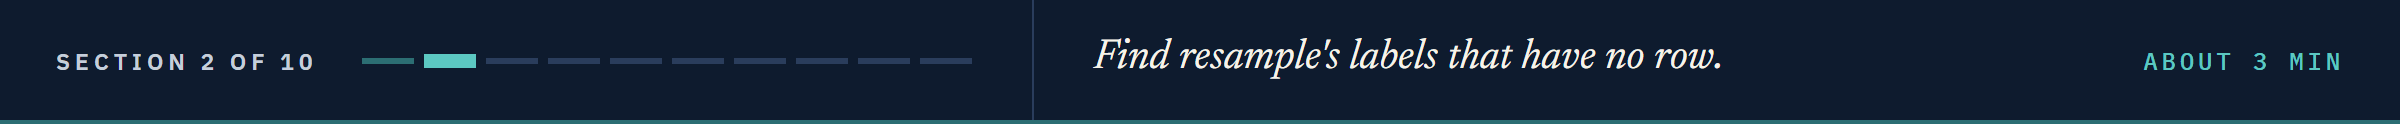

## 4.2 The Label `resample` Prints

Course 1's Treasury Yields case study took month ends with `resample('ME').last()`: 142 rows, each labelled by its calendar month end.
It found one label, 2015-01-31, that the file has no row for.

**Predict 1**

Q. That line gives ten rows for 2026. How many of those ten labels are dates the Treasury file has no row for? Write down a number.

### Course 1's Line on 2026

In [7]:
# Course 1's line: each calendar month's last value
by_resample = ten.resample('ME').last()
labels_2026 = by_resample.loc['2026'].index
# each label, its weekday, and whether the file has a row on that date
for label in labels_2026:
    print(label.date(), label.strftime('%A'), label in ten.index)
# difference keeps the labels the file does not have, as in notebook 03
off_file = labels_2026.difference(ten.index)
print(len(off_file), 'of the', len(labels_2026), 'labels have no row')

2026-01-31 Saturday False
2026-02-28 Saturday False
2026-03-31 Tuesday True
2026-04-30 Thursday True
2026-05-31 Sunday False
2026-06-30 Tuesday True
2026-07-31 Friday True
2026-08-31 Monday True
2026-09-30 Wednesday True
2026-10-31 Saturday False
4 of the 10 labels have no row


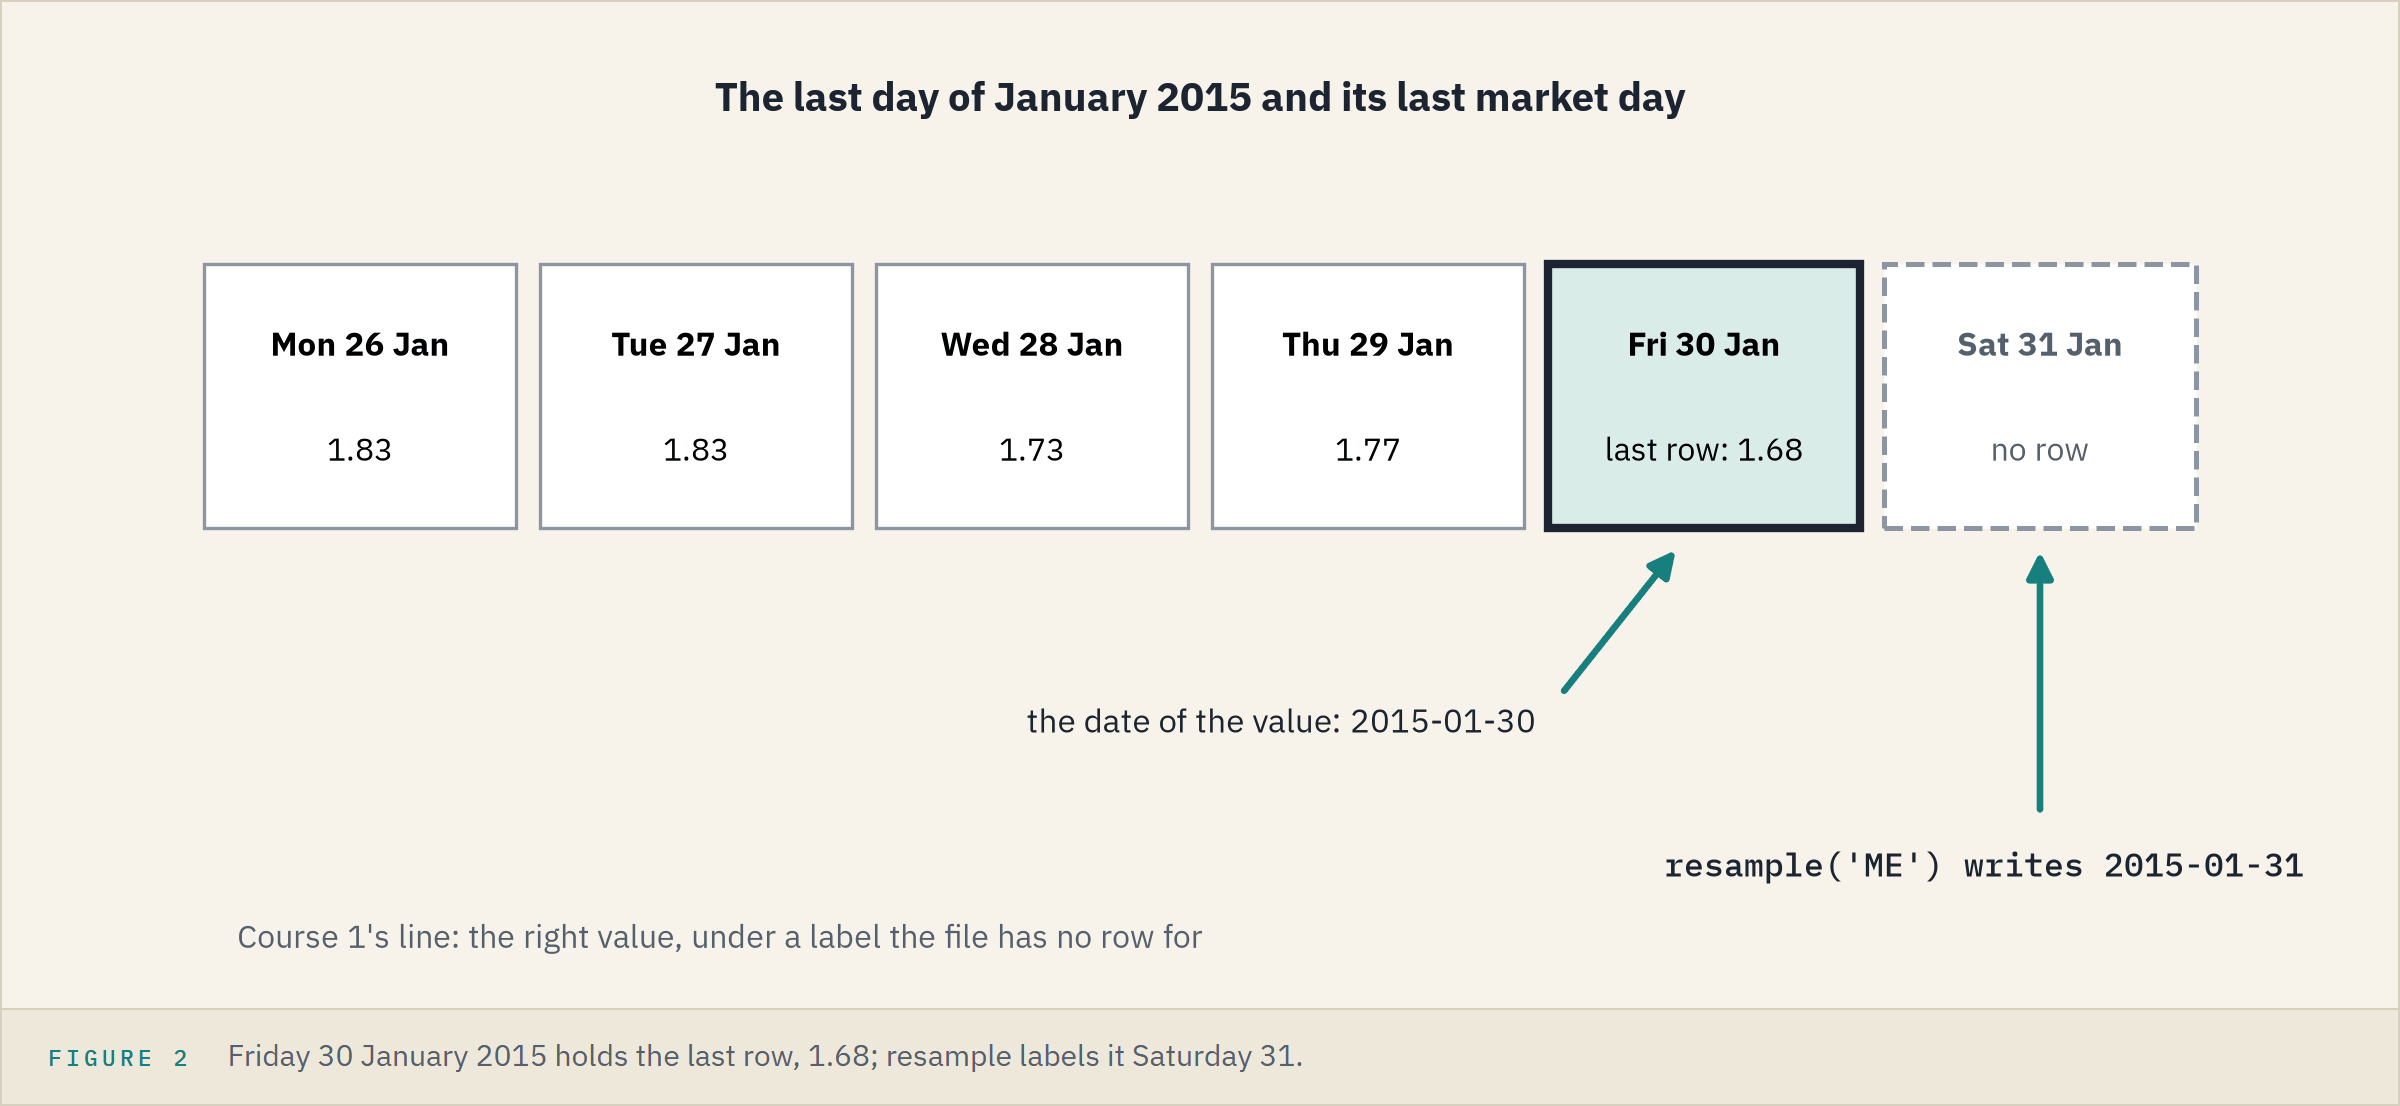

4: January, February and May end on a weekend, and 2026-10-31 is after the file's last row.
The value under each is right: January's 4.26 is Friday 30 January's.
The label is the period's calendar end, not the date of the value.

### A Join on Those Labels

Q. The pack joins the 2 Yr to these labels to build a month-end 2s10s. What does it find?

In [8]:
# join the 2 Yr on resample's labels, with Course 1's .join() on row labels
monthly = pd.DataFrame({'10 Yr': by_resample}).join(treasury['2 Yr'])
print(monthly['2 Yr'].count(), 'of', len(monthly), 'months found a 2 Yr')
monthly.loc['2026']

99 of 142 months found a 2 Yr


,10 Yr,2 Yr
date,,
2026-01-31,4.26,NaN
2026-02-28,3.97,NaN
2026-03-31,4.30,3.79
2026-04-30,4.40,3.88
2026-05-31,4.45,NaN
2026-06-30,4.44,4.14
2026-07-31,4.75,4.28
2026-08-31,4.75,4.34
2026-09-30,5.29,4.88


Nothing raised an error.
A month-end 2s10s built on these labels quietly loses 43 months.

**The values are right and the labels are not: a join on 43 of 142 month labels finds no row.**

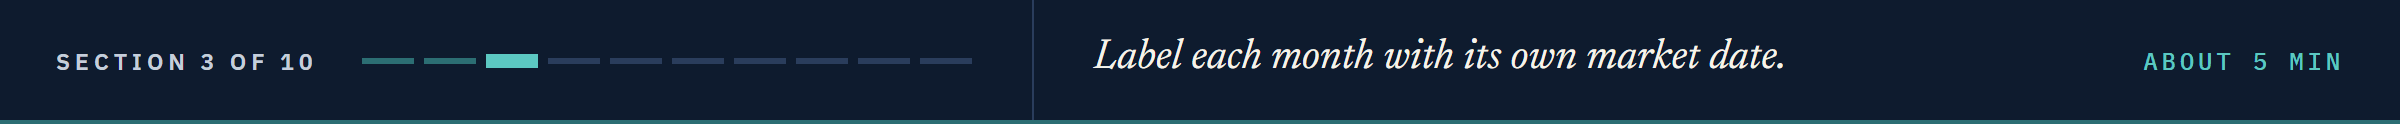

## 4.3 `last_per_period`: Each Month With Its Own Date

The course's rule is each period's last observation, labelled by the date of that observation.

### Append It, Docstring First

Read both docstrings first.
`_check_series` is notebook 03's `_check_index` with one more stop: no missing values.
`pd.Series | pd.DataFrame` reads as notebook 02's `str | None` did: either kind goes in, and the same kind comes back.

In [9]:
%%writefile -a marketdata.py


def _check_series(series: pd.Series, what: str) -> None:
    """Stop unless `series` has unique ascending dates and no missing values (a helper, not part of the API)."""
    _check_index(series.index, what)
    if series.isna().any():
        raise ValueError(f"{what} has {series.isna().sum()} missing values; drop them first with .dropna()")


def last_per_period(data: pd.Series | pd.DataFrame, freq: str) -> pd.Series | pd.DataFrame:
    """The last observation in each week or month, labelled by the date of that observation.

    Units: unchanged. Convention: freq "W-FRI" is the week ending Friday, "ME" the calendar month. Each
    period's row is the last row the data has in it, kept with its own date: September 2026 is labelled
    2026-09-30, and the week of Good Friday 2025 (no row on Friday 2025-04-18) is labelled Thursday 2025-04-17.
    pandas' resample(freq).last() labels by the period end instead. A Series must have no missing values;
    a DataFrame's rows are taken as they are, so a tenor with no value that day stays NaN.
    Raises ValueError for any other freq, or for an index that is not unique ascending dates.
    """
    # the two periods the course uses, with pandas' name for each period
    periods = {"W-FRI": "W-FRI", "ME": "M"}
    if freq not in periods:
        raise ValueError(f"freq must be 'W-FRI' or 'ME', not {freq!r}")
    if isinstance(data, pd.Series):
        _check_series(data, "data")
    else:
        _check_index(data.index, "data")
    # the period each row belongs to
    period_of_row = data.index.to_period(periods[freq])
    # the position of the last row in each period
    positions = pd.Series(range(len(data)), index=data.index).groupby(period_of_row).max()
    # those rows, with their own dates
    return data.iloc[positions.to_numpy()]

Appending to marketdata.py


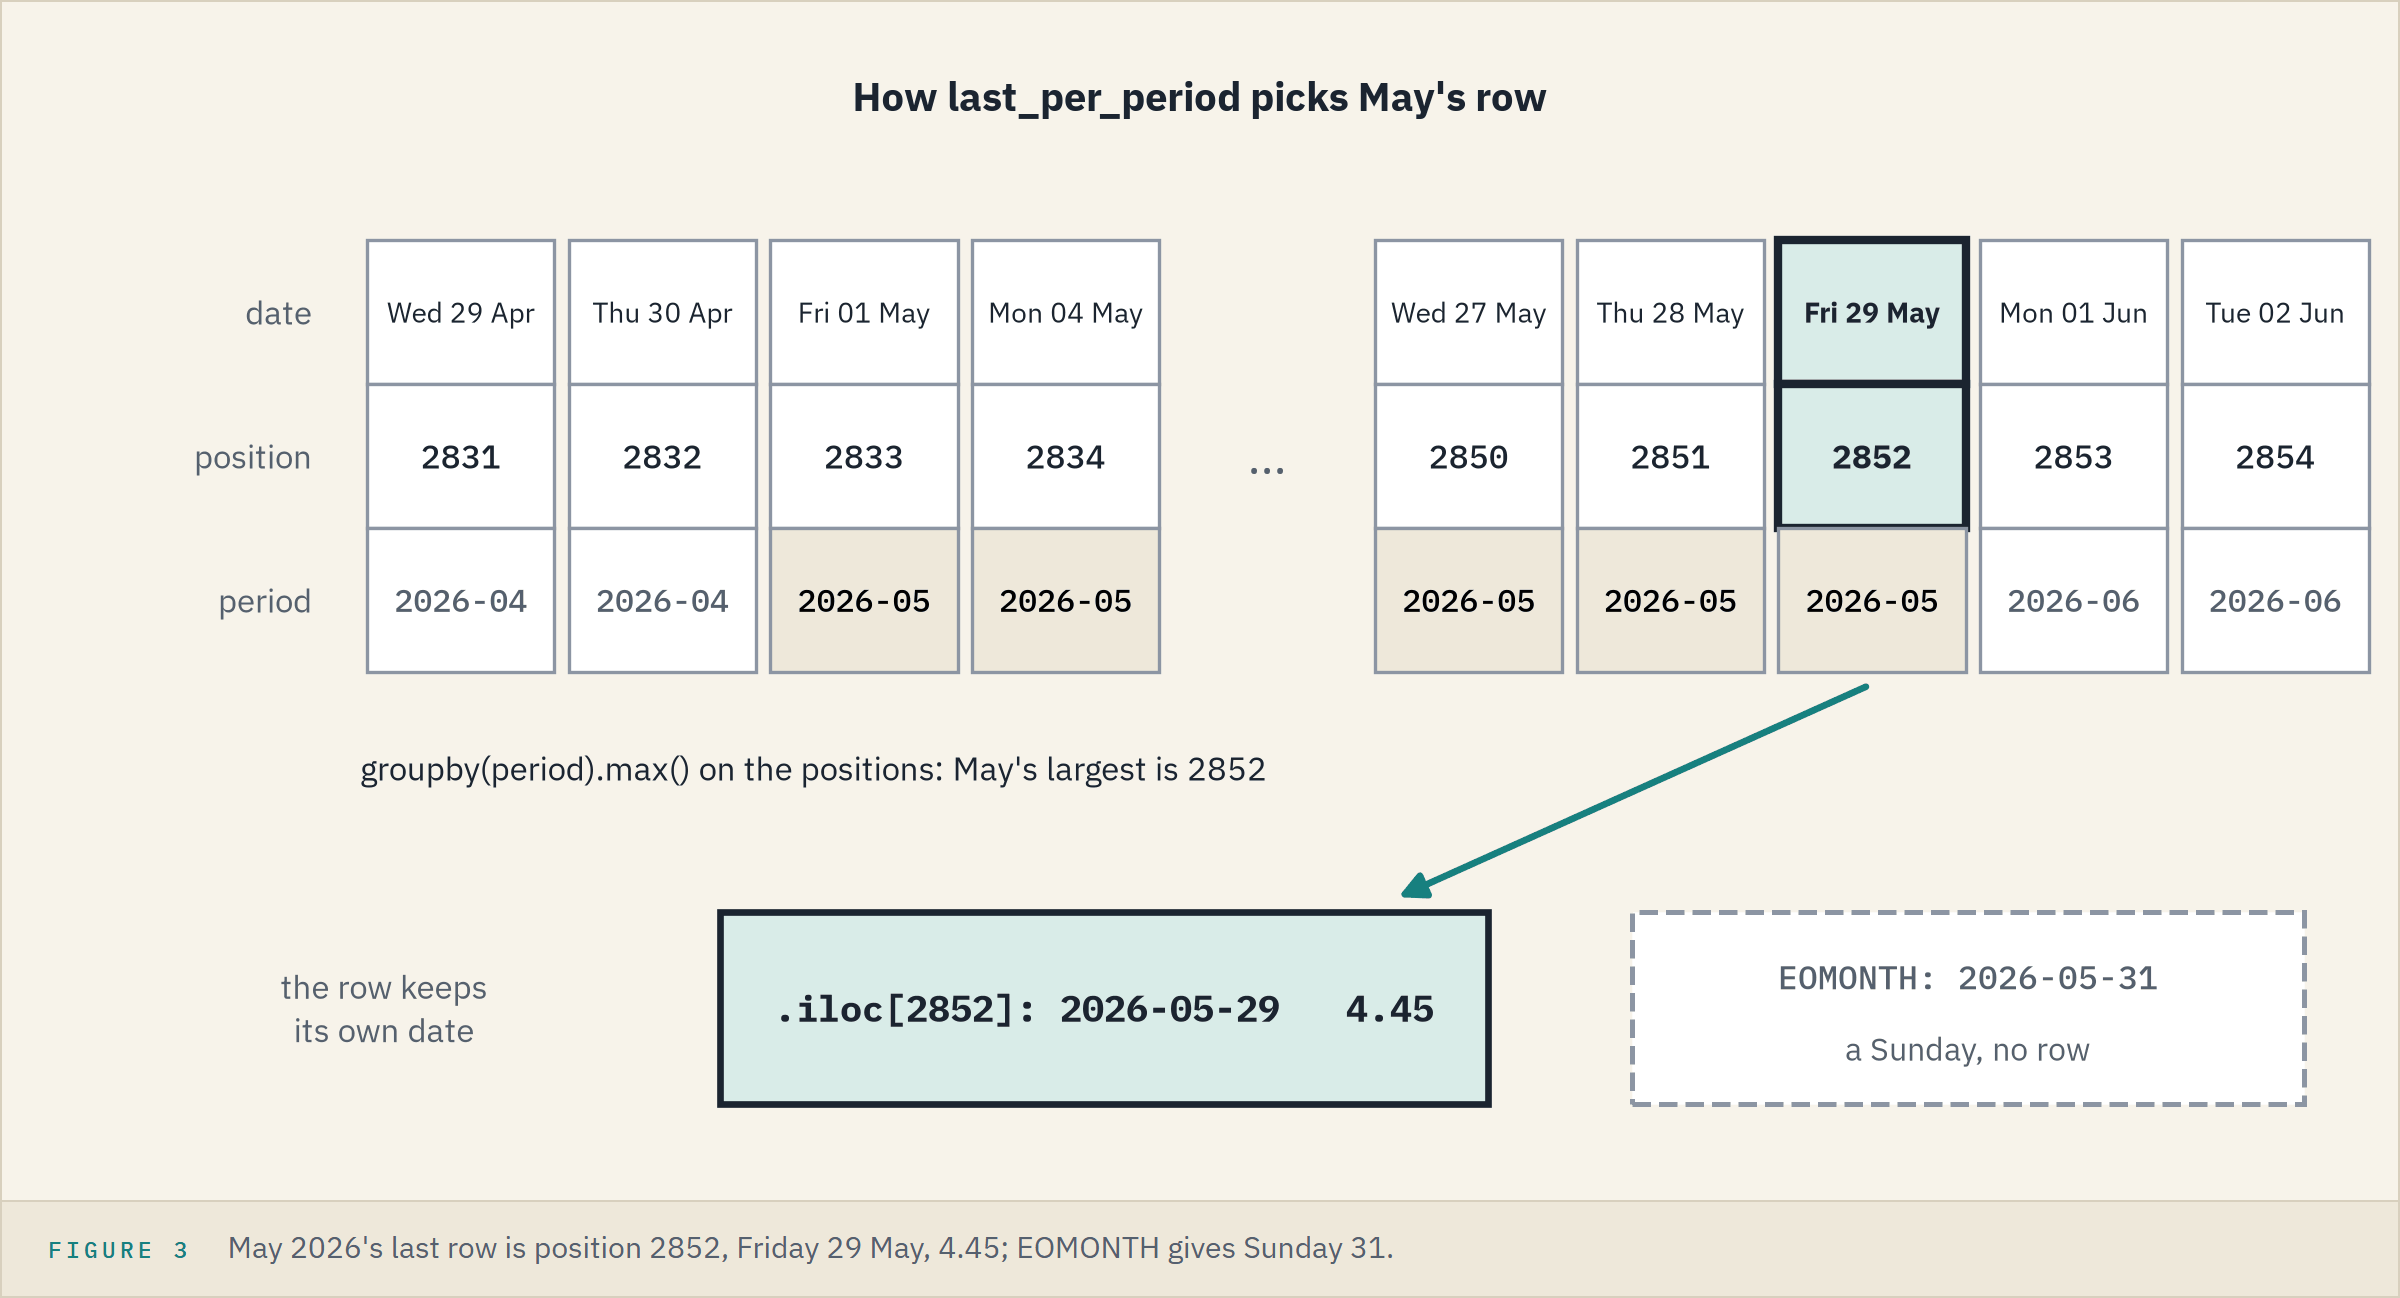

`.to_period('M')` turns each date into its month: pandas names a month `'M'` as a period and `'ME'` as a month end.
Each row gets its position, `groupby(...).max()` keeps each month's largest, and `.iloc[...]` takes those rows with their own dates.

### Month Ends With Real Dates

In [10]:
# reload: the module on disk has changed
importlib.reload(md)
month_end = md.last_per_period(ten, 'ME')
month_end.loc['2026']

date
2026-01-30    4.26
2026-02-27    3.97
2026-03-31    4.30
2026-04-30    4.40
2026-05-29    4.45
2026-06-30    4.44
2026-07-31    4.75
2026-08-31    4.75
2026-09-30    5.29
2026-10-02    5.28
Name: 10 Yr, dtype: float64

### The Same Values, Every Label a Market Day

In [11]:
# the same values as resample's, in the same order; then the labels
print(len(month_end), 'and', len(by_resample), 'rows; values equal:',
      (month_end.to_numpy() == by_resample.to_numpy()).all())
print((month_end.index != by_resample.index).sum(), 'labels differ; every label in the file:',
      month_end.index.isin(ten.index).all())

142 and 142 rows; values equal: True
43 labels differ; every label in the file: True


**Excel side by side.** May 2026, whose calendar end is a Sunday, with Course 2's `EOMONTH`:

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">The calendar end</td><td align="left"><code>by_resample.loc['2026-05'].index[0]</code></td><td align="left"><code>=EOMONTH(DATE(2026,5,15),0)</code></td><td align="left">2026-05-31</td></tr>
<tr><td align="left">Its weekday, counting Monday as 1</td><td align="left">4.2's loop: Sunday</td><td align="left"><code>=WEEKDAY(EOMONTH(DATE(2026,5,15),0),2)</code></td><td align="left">7, a Sunday</td></tr>
<tr><td align="left">The last market date on or before it</td><td align="left"><code>month_end.loc['2026-05'].index[0]</code></td><td align="left"><code>=MAXIFS($A$2:$A$2941,$A$2:$A$2941,"&lt;="&amp;EOMONTH(DATE(2026,5,15),0))</code></td><td align="left">2026-05-29</td></tr>
<tr><td align="left">Its 10 Yr</td><td align="left"><code>month_end.loc['2026-05-29']</code></td><td align="left"><code>=XLOOKUP(MAXIFS($A$2:$A$2941,$A$2:$A$2941,"&lt;="&amp;EOMONTH(DATE(2026,5,15),0)),$A$2:$A$2941,$M$2:$M$2941)</code></td><td align="left">4.45</td></tr>
</table>
<br clear="left">

`MAXIFS` over the dates returns the latest date that meets the condition.
Filled down over one date per month, all 142 dates and 10 Yr values equal `last_per_period`'s.

### Draw Both Labels

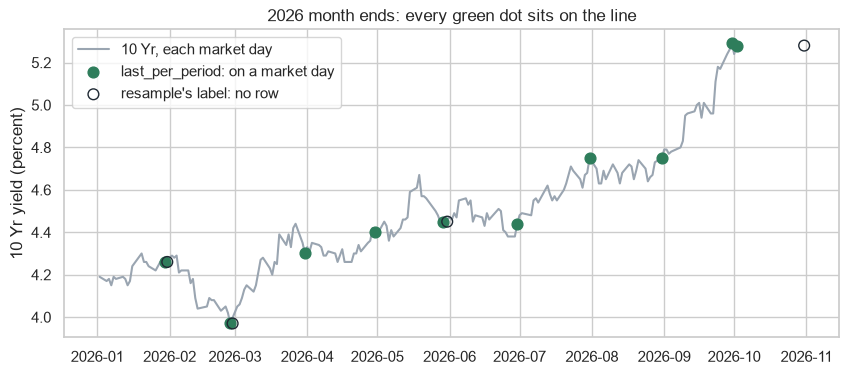

In [12]:
# 2026's daily 10 Yr, the month ends on their own dates, and resample's labels with no row
daily_2026 = ten.loc['2026']
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily_2026.index, daily_2026, color='#9AA5B1', label='10 Yr, each market day')
ax.scatter(month_end.loc['2026'].index, month_end.loc['2026'], s=60, color='#2E7D5B', zorder=3,
           label='last_per_period: on a market day')
# facecolors='none' draws a hollow marker, and edgecolors colours its ring
ax.scatter(off_file, by_resample.loc[off_file], s=60, facecolors='none', edgecolors='#1F2933',
           zorder=3, label="resample's label: no row")
ax.set_title('2026 month ends: every green dot sits on the line')
ax.set_ylabel('10 Yr yield (percent)')
ax.legend()
plt.show()

### A Period It Was Not Built For

In [13]:
# a quarter end: not one of the course's two periods
md.last_per_period(ten, 'QE')

ValueError: freq must be 'W-FRI' or 'ME', not 'QE'

**`last_per_period` keeps resample's 142 values and writes the real date: every label a market day, equal to Excel's `MAXIFS` then `XLOOKUP`.**

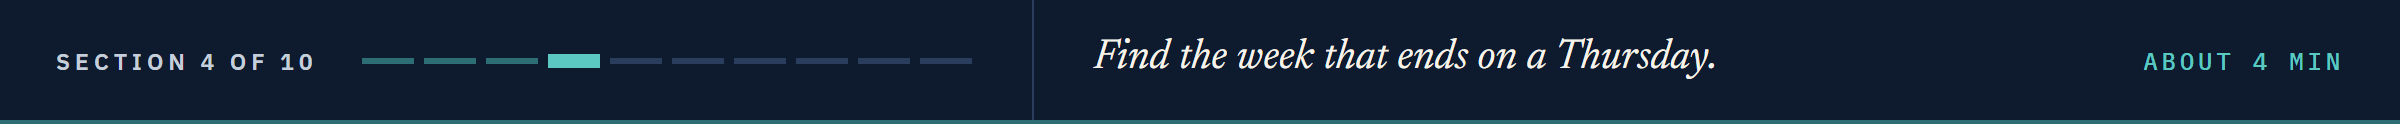

## 4.4 The Week of Good Friday 2025

Weeks end on Friday: Course 1's Trade Blotter case study used `resample('W-FRI')` in an exercise.
Good Friday, 2025-04-18, is one of notebook 03's missing weekdays.

### That Week's Rows

In [14]:
# Monday 14 to Friday 18 April 2025
ten.loc['2025-04-14':'2025-04-18']

date
2025-04-14    4.38
2025-04-15    4.35
2025-04-16    4.29
2025-04-17    4.34
Name: 10 Yr, dtype: float64

### Both Labels

In [15]:
# each week's last row with its own date, and Course 1's resample line on weeks
weekly = md.last_per_period(ten, 'W-FRI')
weekly_resample = ten.resample('W-FRI').last()
print(len(weekly), 'weeks')
# three weeks around Good Friday: resample's label against last_per_period's
around = weekly.loc['2025-04-11':'2025-04-25']
pd.DataFrame({'resample': weekly_resample.loc['2025-04-11':'2025-04-25'].index,
              'last_per_period': around.index, '10 Yr': around.to_numpy()})

614 weeks


,resample,last_per_period,10 Yr
0,2025-04-11,2025-04-11,4.48
1,2025-04-18,2025-04-17,4.34
2,2025-04-25,2025-04-25,4.29


### Draw the Week

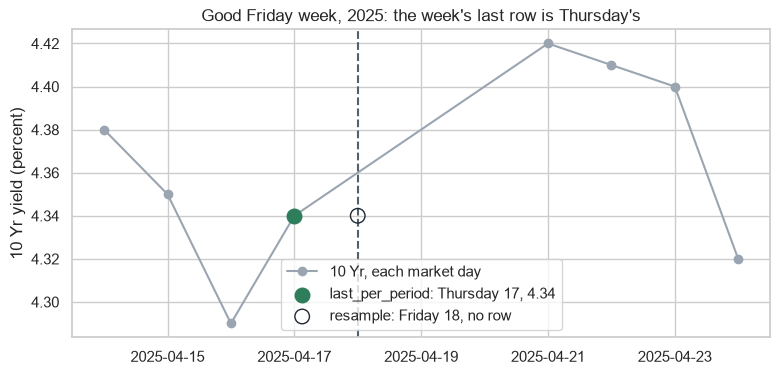

In [16]:
# 14 to 24 April 2025; Good Friday has no row
days = ten.loc['2025-04-14':'2025-04-24']
good_friday = pd.Timestamp('2025-04-18')
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(days.index, days, marker='o', color='#9AA5B1', label='10 Yr, each market day')
ax.scatter(around.index[1:2], around.iloc[1:2], s=110, color='#2E7D5B', zorder=3,
           label='last_per_period: Thursday 17, 4.34')
ax.scatter([good_friday], [weekly_resample.loc[good_friday]], s=110, facecolors='none',
           edgecolors='#1F2933', zorder=3, label='resample: Friday 18, no row')
ax.axvline(good_friday, color='#52606D', linestyle='--')
ax.set_title("Good Friday week, 2025: the week's last row is Thursday's")
ax.set_ylabel('10 Yr yield (percent)')
ax.legend(loc='lower center')
plt.show()

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">The Friday ending a date's week</td><td align="left"><code>'W-FRI'</code></td><td align="left"><code>=A2+MOD(6-WEEKDAY(A2),7)</code></td><td align="left">2025-04-16 gives 2025-04-18; Saturday 2025-04-19 gives 2025-04-25</td></tr>
<tr><td align="left">That week's last market date</td><td align="left"><code>around.index[1]</code></td><td align="left"><code>=MAXIFS($A$2:$A$2941,$A$2:$A$2941,"&lt;="&amp;DATE(2025,4,18))</code></td><td align="left">2025-04-17</td></tr>
</table>
<br clear="left">

`MOD(n,7)` is the remainder after dividing by 7, here the days from the date to its Friday.
`WEEKDAY` without its 2 counts Sunday as 1, as notebook 03 showed.

**Predict 2**

Q. Good Friday 2025's week ends on a Thursday. How many of the file's 614 weeks end on a day other than Friday?

A) 8: the Good Fridays
B) 20
C) 126: every weekday with no row

### Weeks Without a Friday

In [17]:
# dayofweek counts Monday as 0, so Friday is 4, as in notebook 03
not_friday = weekly.index[weekly.index.dayofweek != 4]
print(len(not_friday), 'of', len(weekly), 'weeks end before Friday')
not_friday.strftime('%A').value_counts()

20 of 614 weeks end before Friday


date
Thursday    20
Name: count, dtype: int64

B: 20, each ending on its Thursday.
They are the 20 Fridays among notebook 03's missing weekdays: 8 Good Fridays and 12 other Friday holidays.
Filled over all 614 Fridays, Excel's `MAXIFS` gives the same 20 dates.

### Two Tests for the Labels

They read the real file, so each asserts a fact about real dates.

In [18]:
%%writefile -a test_marketdata.py


def read_treasury() -> pd.DataFrame:
    """The Treasury par yield file in this folder: one row per market date, yields in percent."""
    return pd.read_csv(HERE / "treasury_par_yields.csv", parse_dates=["date"], index_col="date")


def test_month_end_label_is_observation_date():
    ten = read_treasury()["10 Yr"]
    month_end = md.last_per_period(ten, "ME")
    assert month_end.loc["2026-09"].index[0] == pd.Timestamp("2026-09-30")
    assert month_end.loc["2026-09-30"] == 5.29
    # May 2026 ends on Sunday 31, so its label is the last market day, Friday 29
    assert pd.Timestamp("2026-05-29") in month_end.index and pd.Timestamp("2026-05-31") not in month_end.index


def test_good_friday_week_takes_thursday():
    ten = read_treasury()["10 Yr"]
    weekly = md.last_per_period(ten, "W-FRI")
    # no row on Good Friday 2025-04-18, so the week is labelled by Thursday's row
    assert pd.Timestamp("2025-04-17") in weekly.index
    assert pd.Timestamp("2025-04-18") not in weekly.index
    assert weekly.loc["2025-04-17"] == ten.loc["2025-04-17"]

Appending to test_marketdata.py


In [19]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...............                                                          [100%]
15 passed in 0.50s



**A week with no Friday row ends on its Thursday, and the label says so: 20 of 614 weeks, tested.**

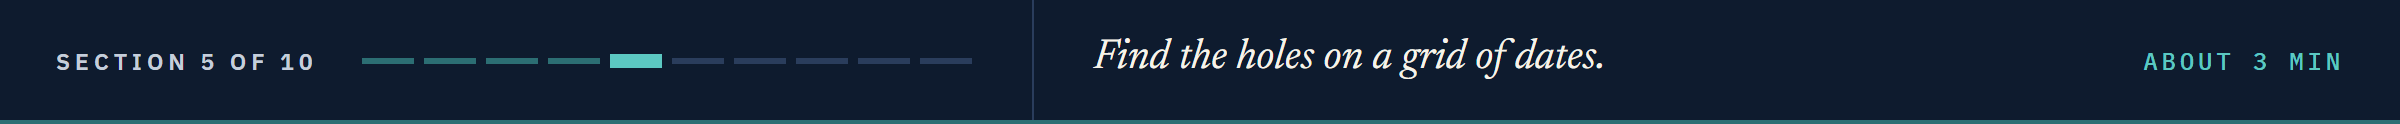

## 4.5 `asfreq`: a Grid of Dates

pandas has a second way to change frequency: `asfreq`.

**Predict 3**

Q. `ten.asfreq('W-SAT')` puts the 10 Yr on a grid of Saturdays. How many Saturdays come back with a value?

A) nearly all: each takes Friday's
B) none
C) the call stops with an error

### A Grid of Saturdays

In [20]:
# W-SAT: a grid of every Saturday in the file's span
saturdays = ten.asfreq('W-SAT')
print(len(saturdays), 'Saturdays,', saturdays.count(), 'with a value')

613 Saturdays, 0 with a value


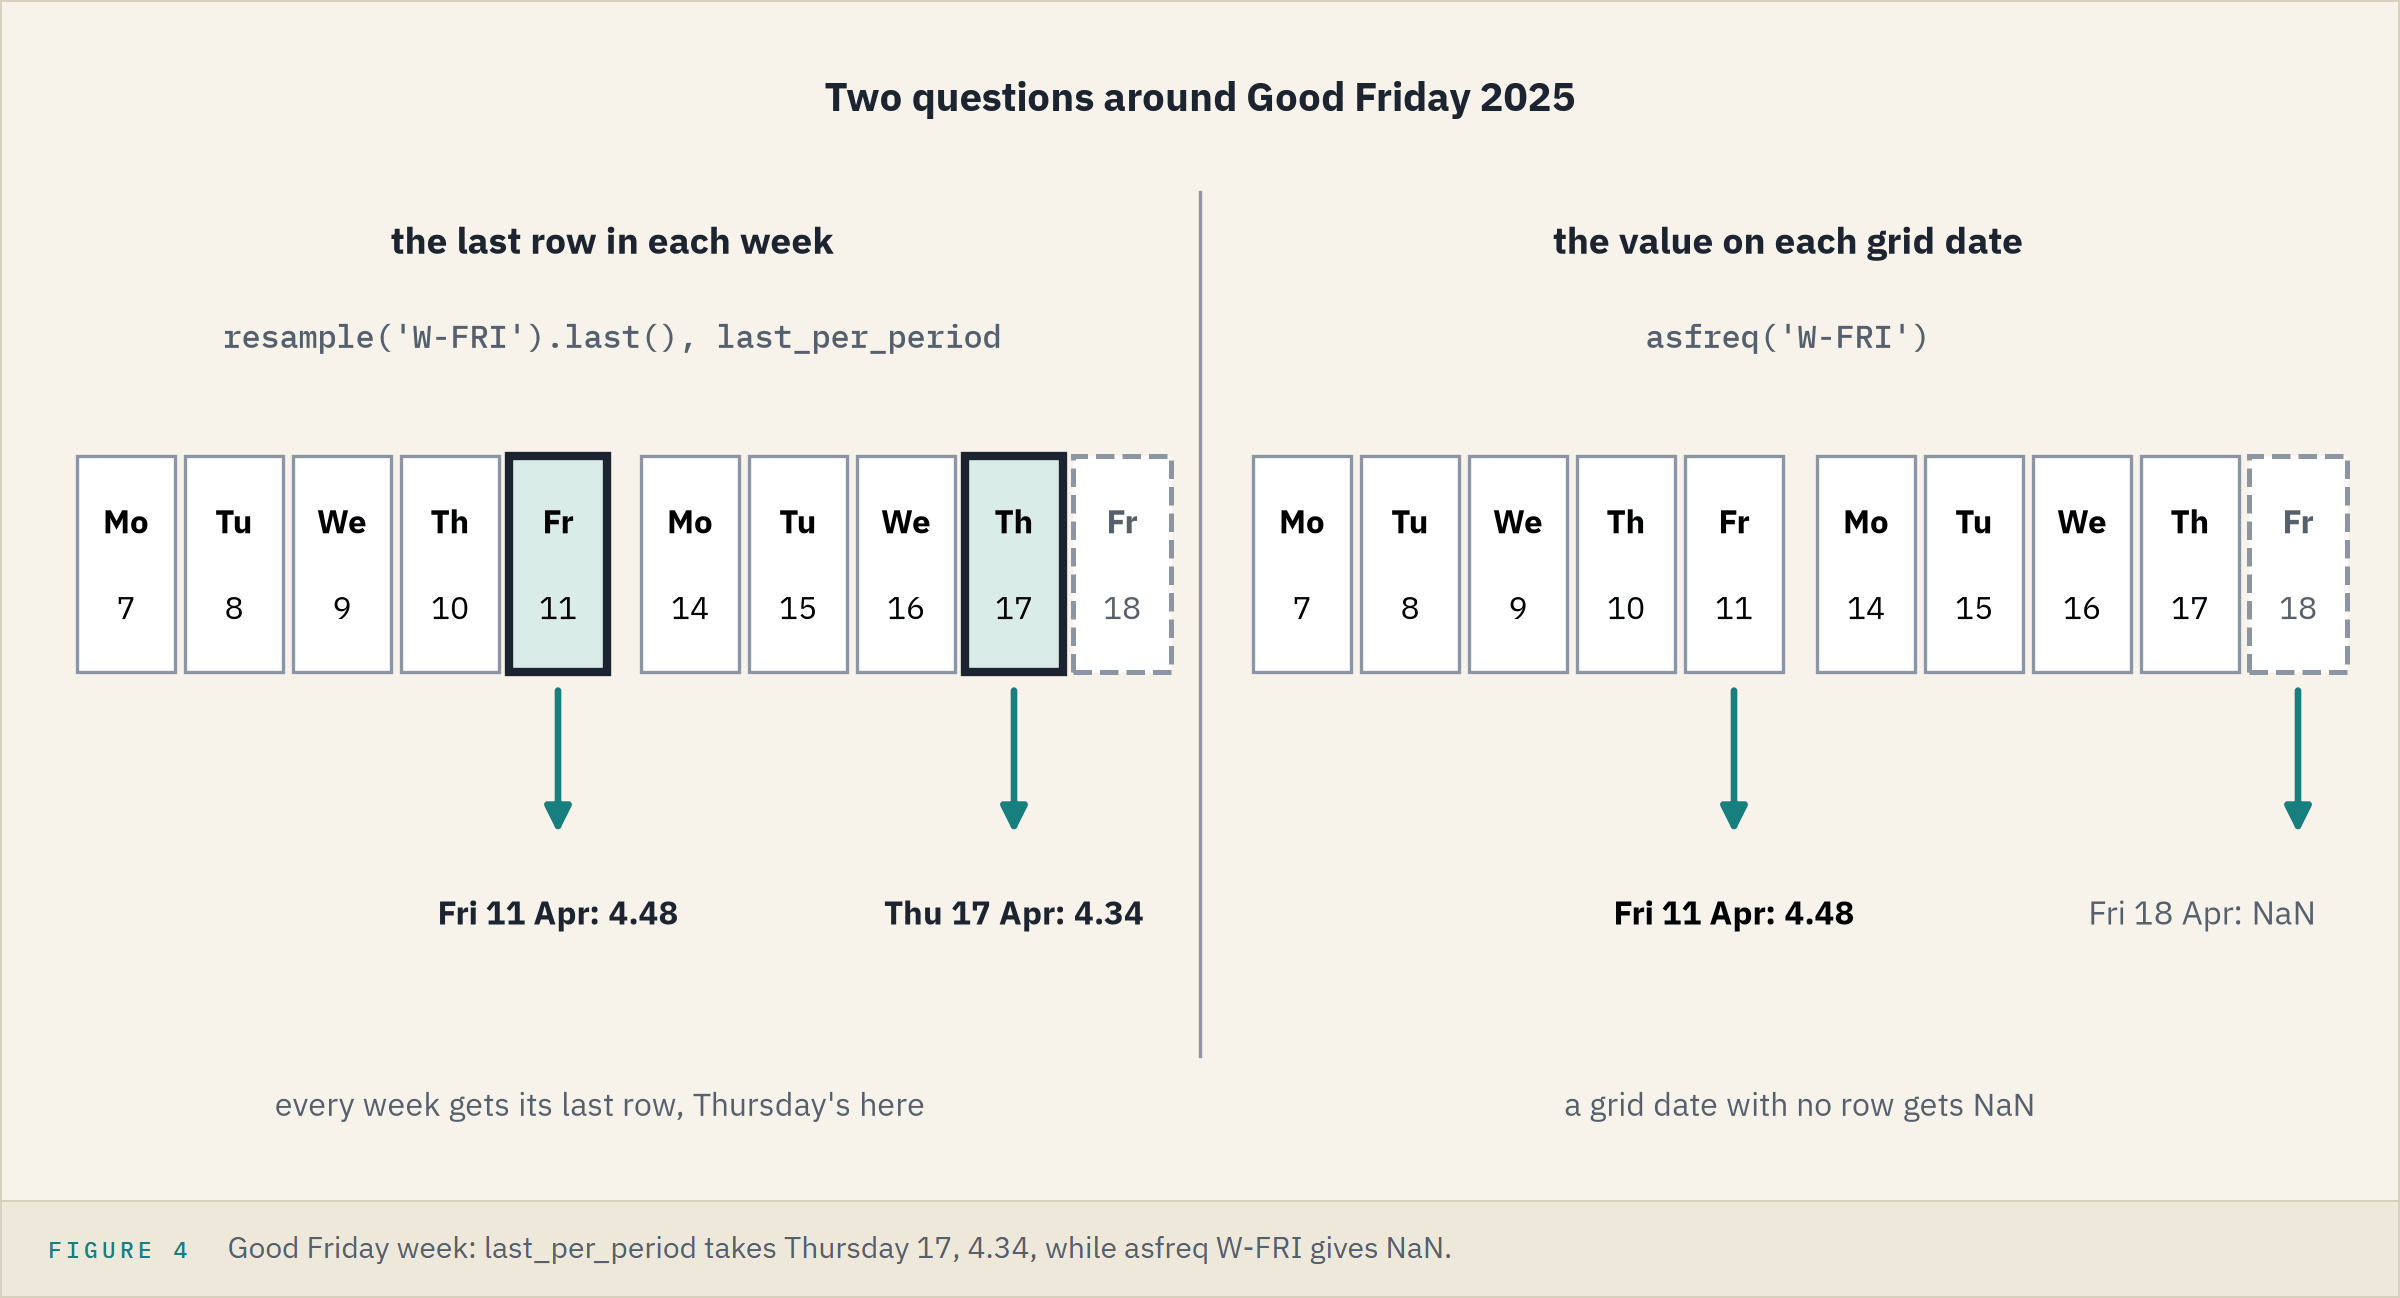

B: `asfreq` asks for the value on each grid date itself, and the file has no Saturday rows.

### Fridays and Month Ends

In [21]:
# the same question on a grid of Fridays and a grid of calendar month ends
friday_grid, month_end_grid = ten.asfreq('W-FRI'), ten.asfreq('ME')
print(len(friday_grid), 'Fridays,', friday_grid.isna().sum(), 'NaN')
print(len(month_end_grid), 'month ends,', month_end_grid.isna().sum(), 'NaN; the last',
      month_end_grid.index[-1].date())

614 Fridays, 20 NaN
141 month ends, 42 NaN; the last 2026-09-30


The 20 are 4.4's weeks with no Friday.
The 42 month ends fall on a weekend or a holiday, and October drops out: its calendar end is after the file's last row.
42 and October make resample's 43 labels with no row.

### Every Weekday

In [22]:
# 'B' is a grid of weekdays; its NaN dates against notebook 03's missing_weekdays
weekday_grid = ten.asfreq('B')
holes = weekday_grid.index[weekday_grid.isna()]
print(len(weekday_grid), 'weekdays,', len(holes), 'NaN; the same dates as missing_weekdays:',
      holes.equals(md.missing_weekdays(ten.index)))

3066 weekdays, 126 NaN; the same dates as missing_weekdays: True


An exact lookup on a date with no row is notebook 03's `XLOOKUP` `#N/A`.
Filling the holes is notebook 03's forward fill, for display only.

**`asfreq` asks for the value on each grid date and leaves `NaN` where the market had no row: good for finding holes, never for a level.**

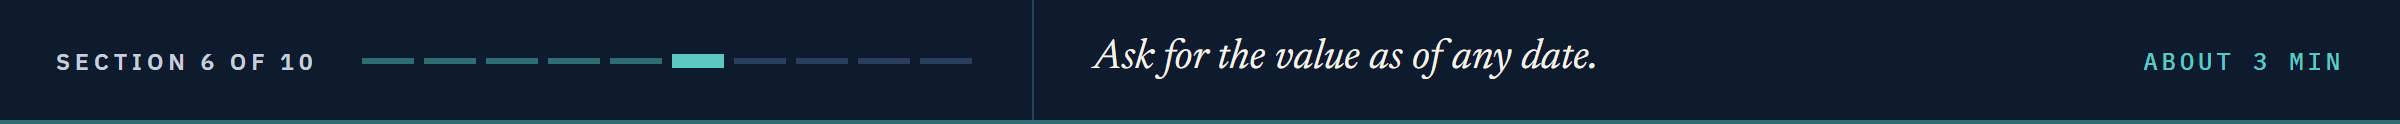

## 4.6 The As-Of Value: `value_as_of`

A report runs on Labor Day, and a client asks for the 10-year as of a Saturday.
The as-of value is the last observation on or before the date, and it should say which row it took.
Course 1's Treasury Yields case study used `XLOOKUP` with -1 once, on a month end.

### Append It, Docstring First

Read the docstring first.
`tuple[pd.Timestamp, float]` says it returns two things, a date and a value, to unpack into two names as Course 1's loops unpacked pairs.
`searchsorted(as_of, side='right')` is where the date would go among the sorted dates, after an equal one, so one less is the last row on or before it.

In [23]:
%%writefile -a marketdata.py


def value_as_of(series: pd.Series, as_of) -> tuple[pd.Timestamp, float]:
    """The date and value of the last observation on or before `as_of`.

    Units: the value has the series' units. Convention: the as-of value; on a holiday or weekend it is
    the previous market day's value. Excel: =XLOOKUP(as_of, dates, values, , -1).
    Raises ValueError if as_of is before the first observation, the series has missing values, or its
    index is not unique ascending dates.
    """
    _check_series(series, "series")
    as_of = pd.Timestamp(as_of)
    # stop before the start: there is no value to carry
    if as_of < series.index[0]:
        raise ValueError(f"{as_of.date()} is before the first observation, {series.index[0].date()}")
    # the position of the last date on or before as_of
    position = series.index.searchsorted(as_of, side="right") - 1
    return series.index[position], float(series.iloc[position])

Appending to marketdata.py


### Labor Day, a Saturday, a Market Day

In [24]:
# reload: the module on disk has changed
importlib.reload(md)
# a holiday, a Saturday, and a day with a row
for as_of in ['2026-09-07', '2026-10-03', '2026-09-30']:
    as_of_date, value = md.value_as_of(ten, as_of)
    print(f'as of {as_of}: {value} from {as_of_date.date()}')

as of 2026-09-07: 4.78 from 2026-09-04
as of 2026-10-03: 5.28 from 2026-10-02
as of 2026-09-30: 5.29 from 2026-09-30


**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">As of Labor Day</td><td align="left"><code>md.value_as_of(ten, '2026-09-07')</code></td><td align="left"><code>=XLOOKUP(DATE(2026,9,7),$A$2:$A$2941,$M$2:$M$2941,,-1)</code></td><td align="left">4.78</td></tr>
<tr><td align="left">The date it came from</td><td align="left">its first item</td><td align="left"><code>=XLOOKUP(DATE(2026,9,7),$A$2:$A$2941,$A$2:$A$2941,,-1)</code></td><td align="left">2026-09-04</td></tr>
<tr><td align="left">As of Saturday 3 October</td><td align="left"><code>md.value_as_of(ten, '2026-10-03')</code></td><td align="left"><code>=XLOOKUP(DATE(2026,10,3),$A$2:$A$2941,$M$2:$M$2941,,-1)</code></td><td align="left">5.28</td></tr>
</table>
<br clear="left">

Match mode -1 is the exact date or the next smaller one: the as-of value.

### Draw the Steps

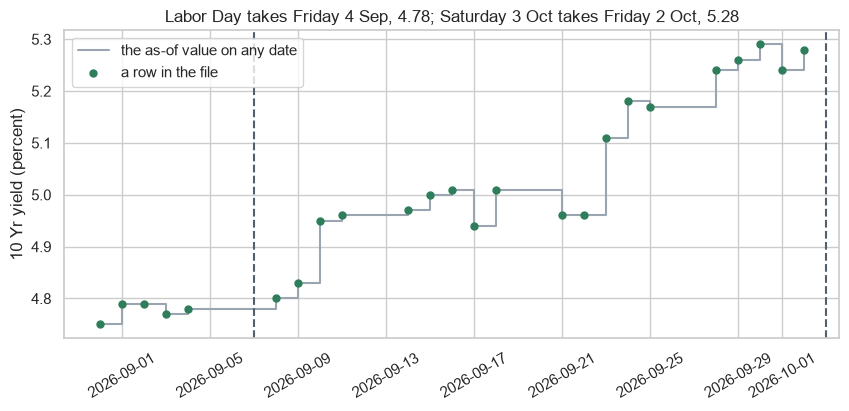

In [25]:
# 31 August to 2 October; where='post' holds each value flat until the next row
span = ten.loc['2026-08-31':'2026-10-02']
fig, ax = plt.subplots(figsize=(10, 4))
ax.step(span.index, span, where='post', color='#9AA5B1', label='the as-of value on any date')
ax.scatter(span.index, span, s=25, color='#2E7D5B', zorder=3, label='a row in the file')
ax.axvline(pd.Timestamp('2026-09-07'), color='#52606D', linestyle='--')
ax.axvline(pd.Timestamp('2026-10-03'), color='#52606D', linestyle='--')
ax.set_title('Labor Day takes Friday 4 Sep, 4.78; Saturday 3 Oct takes Friday 2 Oct, 5.28')
ax.set_ylabel('10 Yr yield (percent)')
ax.tick_params(axis='x', rotation=30)
ax.legend(loc='upper left')
plt.show()

**The as-of value is the last row on or before the date, returned with that row's date: Labor Day's is Friday's 4.78.**

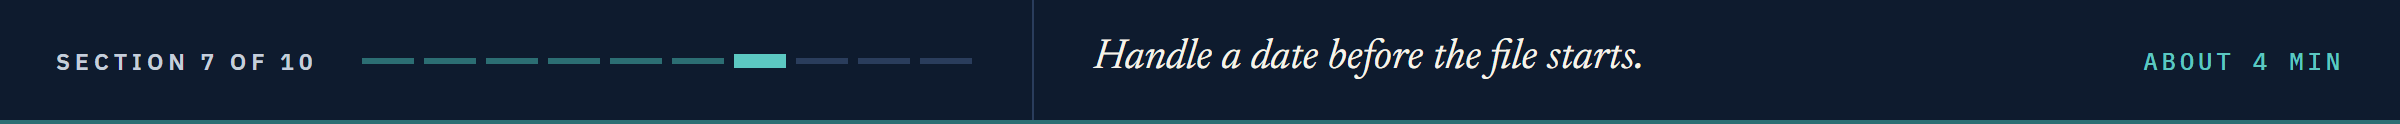

## 4.7 Before the First Row, and a Column With Gaps

The file starts on 2015-01-02.
A report can still ask for a date before it, or read a column that is mostly empty.

**Predict 4**

Q. pandas has the same idea built in, `ten.asof(date)`, which returns the value only. Ask it for 2014-12-31, before the file starts. It returns:

A) a `ValueError`
B) `nan`
C) the first value, 2015-01-02's

### pandas' `asof`, Before the File Starts

In [26]:
# asof on Labor Day, then on a date before the first row
print(ten.asof(pd.Timestamp('2026-09-07')), ten.asof(pd.Timestamp('2014-12-31')))

4.78 nan


B: `nan`, with no error and no date.

### `value_as_of`, Before the File Starts

In [27]:
# the module's function stops instead
md.value_as_of(ten, '2014-12-31')

ValueError: 2014-12-31 is before the first observation, 2015-01-02

**Excel side by side.** `=XLOOKUP(DATE(2014,12,31),$A$2:$A$2941,$M$2:$M$2941,,-1)` shows `#N/A`: no row on or before it.

### A Column With Gaps

In [28]:
# the 1.5 Month bill has yields only from 2025-02-18
md.value_as_of(treasury['1.5 Month'], '2026-09-07')

ValueError: series has 2532 missing values; drop them first with .dropna()

In [29]:
# drop the empty rows first, in a step you can see
print(md.value_as_of(treasury['1.5 Month'].dropna(), '2026-09-07'))

(Timestamp('2026-09-04 00:00:00'), 3.83)


`value_as_of` never drops anything itself, so a gap is never hidden.

### Two Tests for the As-Of Value

In [30]:
%%writefile -a test_marketdata.py


def test_value_as_of_holiday_returns_previous_day():
    ten = read_treasury()["10 Yr"]
    # Labor Day 2026-09-07 has no row: the as-of value is Friday 2026-09-04's
    as_of_date, value = md.value_as_of(ten, "2026-09-07")
    assert as_of_date == pd.Timestamp("2026-09-04")
    assert value == ten.loc["2026-09-04"]


def test_value_as_of_before_start_raises():
    ten = read_treasury()["10 Yr"]
    with pytest.raises(ValueError):
        md.value_as_of(ten, "2014-12-31")

Appending to test_marketdata.py


In [31]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.................                                                        [100%]
17 passed in 0.50s



**Before the file starts `value_as_of` stops where `asof` returns `nan`, and a gap is dropped in a step you can see.**

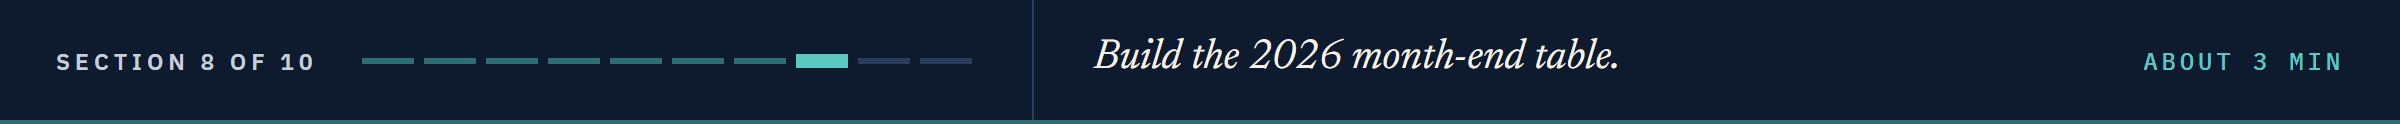

## 4.8 Month-End Levels for 2026

The note's table: the 10-year and 2s10s at each 2026 month end.

### The 10 Yr and 2s10s at Each Month End

In [32]:
# 2s10s in bp: (10 Yr - 2 Yr) x 100, as in Course 1; both columns, one row per month end
curve = pd.DataFrame({'10 Yr': ten, '2s10s_bp': (ten - treasury['2 Yr']) * 100})
month_ends = md.last_per_period(curve, 'ME').loc['2026']
month_ends.round(2)

,10 Yr,2s10s_bp
date,,
2026-01-30,4.26,74.0
2026-02-27,3.97,59.0
2026-03-31,4.30,51.0
2026-04-30,4.40,52.0
2026-05-29,4.45,47.0
2026-06-30,4.44,30.0
2026-07-31,4.75,47.0
2026-08-31,4.75,41.0
2026-09-30,5.29,41.0


Ten real dates.
The 2s10s runs from 30 bp on 2026-06-30 to 74 bp on 2026-01-30, positive at every month end.

**Excel side by side.** On the `MAXIFS` dates in column R, `=(XLOOKUP(R1,$A$2:$A$2941,$M$2:$M$2941)-XLOOKUP(R1,$A$2:$A$2941,$I$2:$I$2941))*100` filled down equals the 2s10s on all 142 months, with a largest gap of 0.0 bp.

### A Pivot Table Grouped by Month

A pivot table is the other way Excel gives one number per month.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Each month's last market date</td><td align="left"><code>month_ends.index</code></td><td align="left">Insert, PivotTable on the 2026 rows, <code>date</code> in Rows grouped by Months, <code>date</code> in Values set to Max</td><td align="left">the ten dates above</td></tr>
<tr><td align="left">The pivot's number for the 10 Yr</td><td align="left"><code>daily_2026.groupby(daily_2026.index.month).max()</code></td><td align="left">The 10 Yr in Values, set to Max</td><td align="left">the month's high: 4.3 in January</td></tr>
</table>
<br clear="left">

In [33]:
# each 2026 month's high against its close
highs = daily_2026.groupby(daily_2026.index.month).max()
gap_bp = (highs.to_numpy() - month_ends['10 Yr'].to_numpy()) * 100
print((gap_bp > 0).sum(), 'of', len(highs), 'months: the high is above the close')

6 of 10 months: the high is above the close


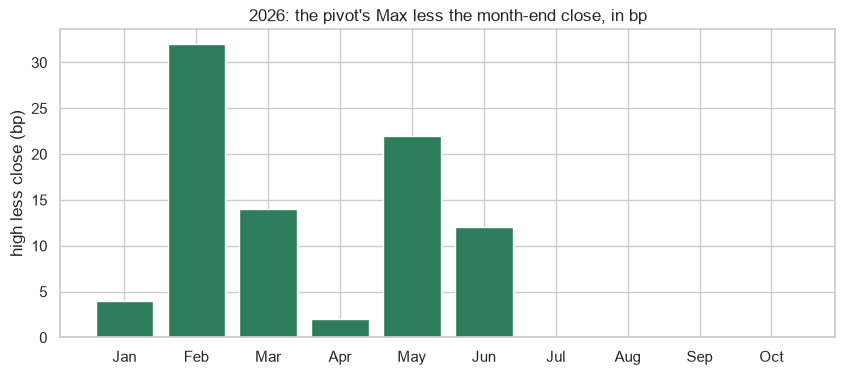

In [34]:
# how far each month's high sits above its close, in bp
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(month_ends.index.strftime('%b'), gap_bp, color='#2E7D5B')
ax.set_title("2026: the pivot's Max less the month-end close, in bp")
ax.set_ylabel('high less close (bp)')
plt.show()

Take the dates from the pivot and the values with `XLOOKUP`: a pivot's Max of a yield is the month's high.

**Ten month ends, each on a market day, the 10 Yr and 2s10s equal to Excel; a pivot's Max is the month's high, not its close, in 6 of 10 months.**

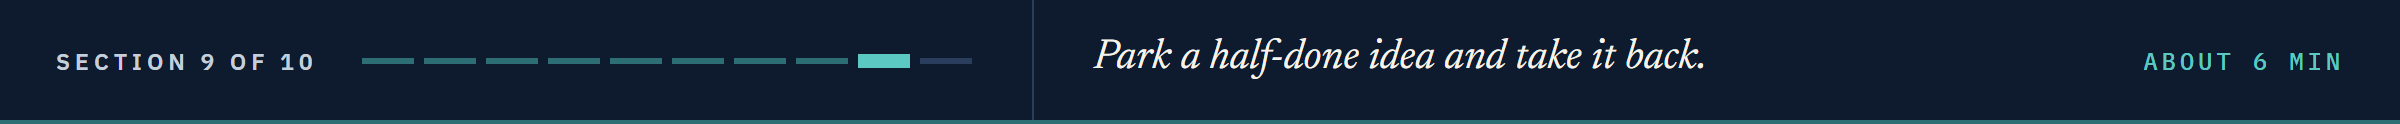

## 4.9 Park an Experiment: `git stash`

The note's last ask: keep any half-finished idea out of the commit.

### Commit the Day

In [35]:
!git -C "{work}" status --short
!git -C "{work}" diff --stat

 M marketdata.py
 M test_marketdata.py
 marketdata.py      | 51 +++++++++++++++++++++++++++++++++++++++++++++++++++
 test_marketdata.py | 37 +++++++++++++++++++++++++++++++++++++
 2 files changed, 88 insertions(+)


In [36]:
!git -C "{work}" add marketdata.py test_marketdata.py
!git -C "{work}" commit -q -m "Notebook 04: last_per_period and value_as_of"
!git -C "{work}" log --oneline

9f01b1c Notebook 04: last_per_period and value_as_of
a439502 Notebook 03: missing_weekdays, align, and stale_runs
ceea769 Notebook 02: fred_params, parse_fred_observations, and fred_series
a28686d Notebook 01: get_secret, a .gitignore, and .env.example


### An Idea, Half Done

Q. What if a month were stood for by its first observation? You start trying it in the module.

In [37]:
%%writefile -a marketdata.py


# experiment, not finished: a month stood for by its first observation?
def month_first(series: pd.Series) -> pd.Series:
    """The first observation of each calendar month (an experiment)."""
    return series.resample("ME").first()

Appending to marketdata.py


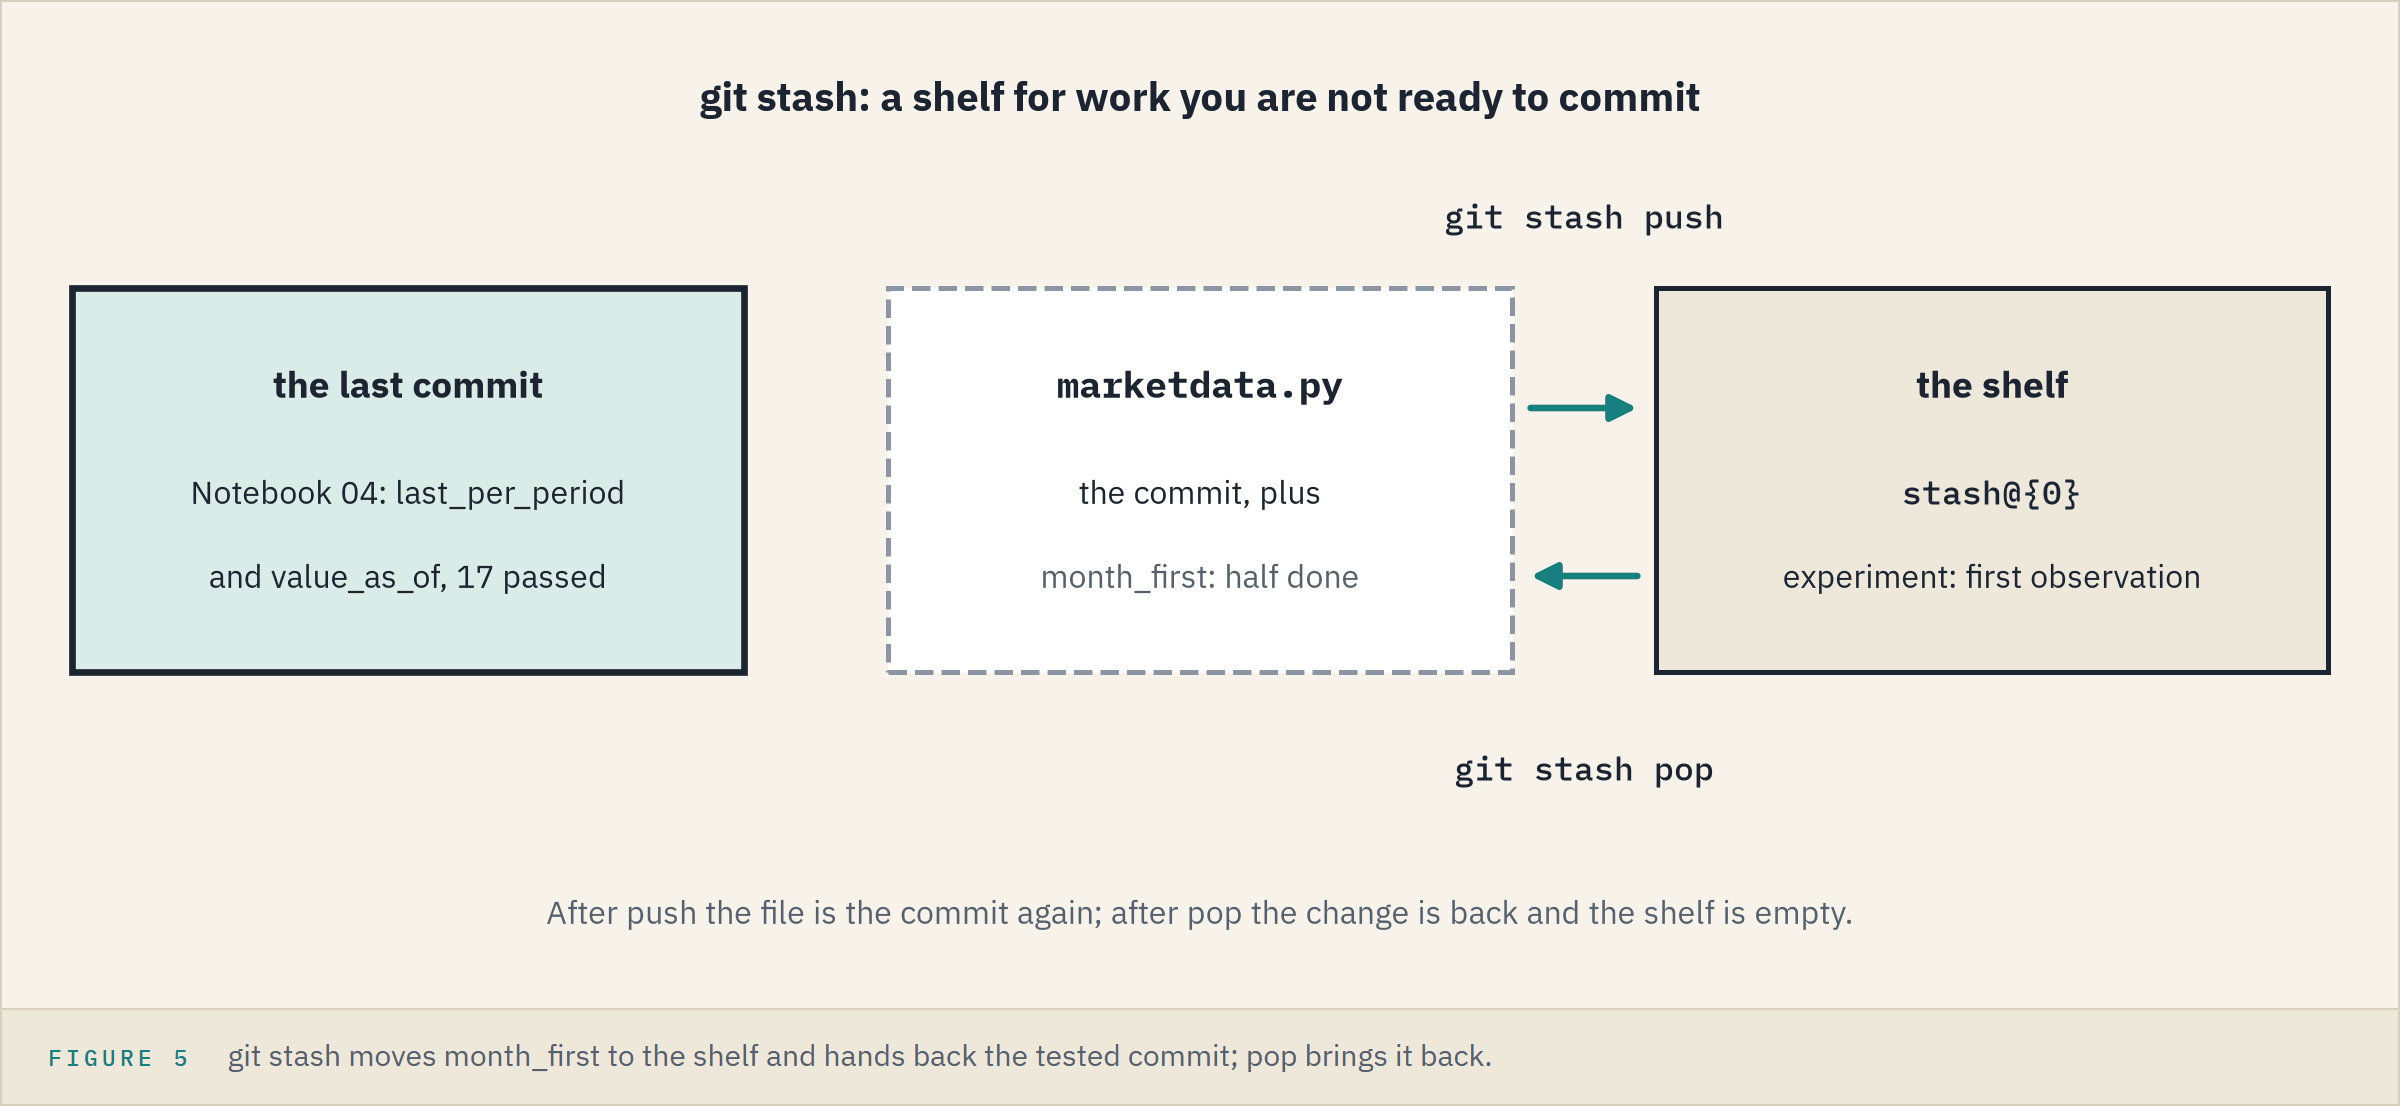

A colleague wants the month-end table now, from the tested module.
`git stash` puts the change on a shelf and hands back the file as committed.

### Put It on the Shelf

In [38]:
!git -C "{work}" stash push -m "experiment: first observation of each month"
!git -C "{work}" stash list
!git -C "{work}" status --short

Saved working directory and index state On main: experiment: first observation of each month
stash@{0}: On main: experiment: first observation of each month


### The Tested Module, Untouched

In [39]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.................                                                        [100%]
17 passed in 0.50s



In [40]:
# the file on disk is the commit again; hasattr asks whether the module has a name
importlib.reload(md)
print('month_first in the module:', hasattr(md, 'month_first'))
md.last_per_period(ten, 'ME').loc['2026-07':'2026-09']

month_first in the module: False


date
2026-07-31    4.75
2026-08-31    4.75
2026-09-30    5.29
Name: 10 Yr, dtype: float64

### Take It Back

In [41]:
!git -C "{work}" stash pop -q
!git -C "{work}" stash list
!git -C "{work}" diff --stat

 marketdata.py | 6 ++++++
 1 file changed, 6 insertions(+)


The shelf is empty and the change is back.
4.1 already answered it: the first observation is the month's open, the wrong edge.

### Discard It

In [42]:
# discard it, as Course 2's restore did
!git -C "{work}" restore marketdata.py
!git -C "{work}" status --short
!git -C "{work}" log --oneline

9f01b1c Notebook 04: last_per_period and value_as_of
a439502 Notebook 03: missing_weekdays, align, and stale_runs
ceea769 Notebook 02: fred_params, parse_fred_observations, and fred_series
a28686d Notebook 01: get_secret, a .gitignore, and .env.example


`git stash drop` throws a shelved change away without bringing it back.

**`git stash` parks half-done work and hands back the committed file; `pop` returns it, and nothing half-done reaches a commit.**

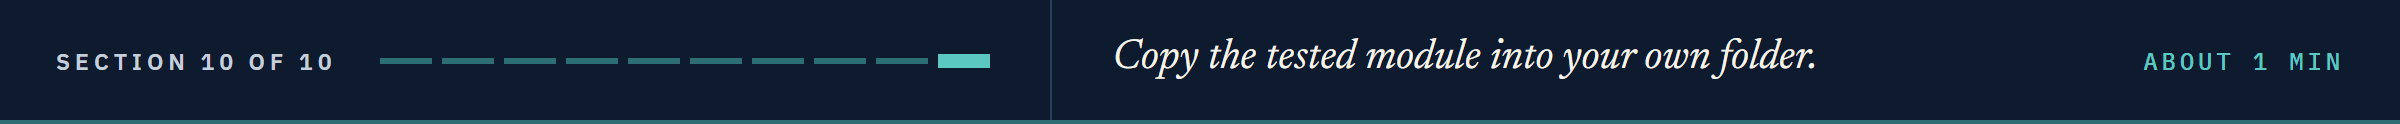

## Bring It Home

Copy the work folder's two files into `my_bondmath`, with the Treasury file the tests now read, test them, and commit.
The copy replaces your two files, so anything of your own must be in the work folder first.
In a PowerShell terminal in VS Code, with the course's `.venv` active:

```powershell
# the work folder: use the name your setup cell printed
$work = "$env:TEMP\pfi_course3_04_k4w7q2xr"
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$work\marketdata.py", "$work\test_marketdata.py" .
# the Treasury file: read by the tests from today, never committed
Copy-Item "$work\treasury_par_yields.csv" .
python -m pytest -q test_marketdata.py
git status --short
git add marketdata.py test_marketdata.py
git commit -m "Notebook 04: last_per_period and value_as_of"
```

pytest shows `17 passed`, and `git status` lists the Treasury file as `??`: it stays out of the commit.
In Colab, download the two files from the work folder under `/tmp` instead.
The work folder stays in your temp folder; the system clears it in time.

## You Can Now

By the end of this notebook, you can:

* Say which observation stands for a month or a week, and why the course takes the close, not the mean.
* Read `resample`'s period-end labels, and find the ones the file has no row for.
* Take each period's last row with its own date, `last_per_period`, tied to `MAXIFS` and `XLOOKUP`.
* Show a week with no Friday, labelled by its Thursday.
* Use `asfreq` to find holes on a calendar grid, never for a level.
* Give the value as of any date, with the date it came from, `value_as_of`, tied to `XLOOKUP` with -1.
* Park half-done work with `git stash`, and bring it back with `git stash pop`.

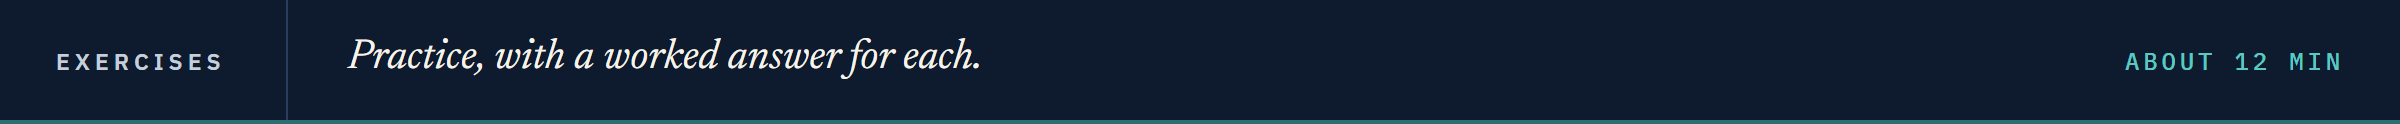

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell under it.
Run the next two cells first: `check`, and the Treasury file.

In [43]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [44]:
# the Treasury file and its 10 Yr, as in the lesson
treasury = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                       float_precision='round_trip')
ten = treasury['10 Yr']

### Exercise 1

Q. Take the weekly 5 Yr with `md.last_per_period`, and keep the weeks whose last row is in September 2026. Store their levels as a list in **ex1_values**, and their labels as `'YYYY-MM-DD'` text in **ex1_labels**.

In [45]:
ex1_values = ...
ex1_labels = ...

In [46]:
check('Exercise 1 the weekly levels', ex1_values, [4.54, 4.78, 4.86, 4.98])
check('Exercise 1 the labels', ex1_labels,
      ['2026-09-04', '2026-09-11', '2026-09-18', '2026-09-25'])

Exercise 1 the weekly levels: not attempted yet
Exercise 1 the labels: not attempted yet


### Exercise 2

Q. 2026-01-19, 2026-05-25 and 2026-07-03 are weekdays with no row. Write in a comment which date each as-of value will come from. Then store the three results of `md.value_as_of(ten, day)`, in that order, as a list in **ex2_results**.

In [47]:
# your prediction:
ex2_results = ...

In [48]:
check('Exercise 2 the as-of values', ex2_results,
      [(pd.Timestamp('2026-01-16'), 4.24), (pd.Timestamp('2026-05-22'), 4.56),
       (pd.Timestamp('2026-07-02'), 4.49)])

Exercise 2 the as-of values: not attempted yet


### Exercise 3

Q. Add `month_end_table(curve, tenors)`, docstring first: the month-end levels of the chosen tenor columns, one row per calendar month, labelled by its last market date, from `last_per_period`. Raise `ValueError` naming any tenor that is not a column. Add `test_month_end_table_labels_and_columns`: for `['5 Yr', '30 Yr']` the columns are those two, September 2026 is labelled 2026-09-30, 2026-05-29 is a label, and `['11 Yr']` raises. Run pytest, reload, and store the 2026-09-30 row of `md.month_end_table(treasury, ['5 Yr', '30 Yr'])` as a list in **ex3_row**.

In [49]:
%%writefile -a marketdata.py


# Exercise 3: write month_end_table(curve, tenors) below this line

Appending to marketdata.py


In [50]:
%%writefile -a test_marketdata.py


# Exercise 3: write test_month_end_table_labels_and_columns() below this line

Appending to test_marketdata.py


In [51]:
# run pytest as in the lesson, reload the module, then call your function
ex3_row = ...

In [52]:
check('Exercise 3 the September 2026 row', ex3_row, [5.09, 5.64])

Exercise 3 the September 2026 row: not attempted yet


### Exercise 4: AI check

You gave an assistant the docstring below as the prompt; the function came back, written for this course in the style of an assistant's answer, and holds one bug.

In [53]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
def month_end_levels(series):
    """Month-end levels of a daily yield series: one value per calendar month.

    Units: unchanged (percent for a yield). Convention: each month's value is its month-end
    level, the observation on the last market day of the month. A month that ends on a
    weekend or a holiday takes the value of its last market day.
    """
    # group the daily rows into calendar months and keep one value from each
    return series.resample('ME').first()

Q. The file's last September row is 2026-09-30, at 5.29 percent. Write down what the function gives for 2026-09-30, then run the test under it.

In [54]:
# the test, written from the docstring before the code is trusted
levels = month_end_levels(ten)
assert levels.loc['2026-09-30'] == 5.29, f"September 2026 is {levels.loc['2026-09-30']}, not 5.29"
print('September 2026 is 5.29 percent, its month-end level')

AssertionError: September 2026 is 4.79, not 5.29

Q. Fix the function, then run it and the test again until the test passes. Store `month_end_levels(ten).loc['2026-09-30']` in **ex4_september**, and the number of months it returns in **ex4_months**.

In [55]:
ex4_september = ...
ex4_months = ...

In [56]:
check('Exercise 4 September 2026', ex4_september, 5.29)
check('Exercise 4 the number of months', ex4_months, 142)

Exercise 4 September 2026: not attempted yet
Exercise 4 the number of months: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Which observation stands for a month or a week</td><td align="left">The last: 5.29 on 2026-09-30 for September</td></tr>
<tr><td align="left">The date beside it</td><td align="left"><code>last_per_period</code>: 142 months, every label a market day (43 of resample's are not)</td></tr>
<tr><td align="left">A week with no Friday</td><td align="left">Labelled by its Thursday: 20 of 614 weeks</td></tr>
<tr><td align="left">The value as of any date</td><td align="left"><code>value_as_of</code>: Labor Day gives Friday's 4.78, and says so</td></tr>
<tr><td align="left">The 2026 month ends</td><td align="left">The 10 Yr and 2s10s, equal to Excel's <code>MAXIFS</code> and <code>XLOOKUP</code></td></tr>
<tr><td align="left">Two tested functions, nothing half-done committed</td><td align="left"><code>17 passed</code>, the experiment stashed and discarded</td></tr>
</table>
<br clear="left">

Be proud: every weekly and monthly number you report now carries the date it really comes from.

Next: The Market Dataset case study (notebook 05) caches FRED's series and builds the course's daily dataset.

[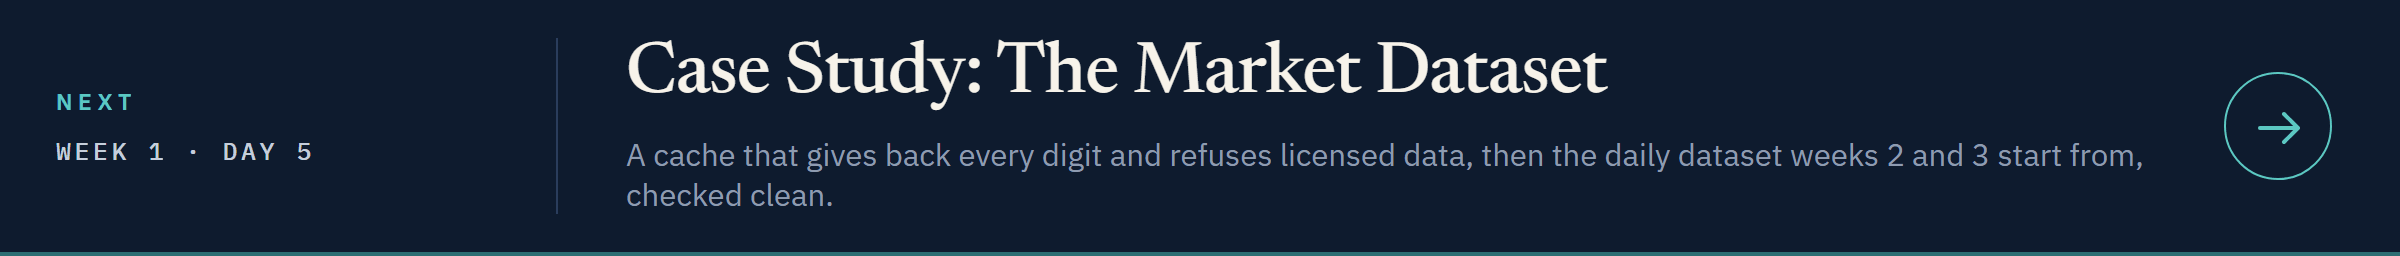](../day5/05_case_study_the_market_dataset.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week1/day5/05_case_study_the_market_dataset.ipynb)